In [1]:
# What is POS Tagging?
#POS Tagging(Part-of-Speech Tagging) is the process of assigning a grammatical category to each word in a sentence.

In [ ]:
# Install spacy
!pip install spacy


In [2]:
# Download the English model:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 91.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
import spacy
nlp = spacy.load("en_core_web_sm")

In [4]:
#1. Basic POS Tagging
text = "There are beautiful flowers in the garden."
doc = nlp(text)
for token in doc:
    print(token.text, token.pos_)

There PRON
are VERB
beautiful ADJ
flowers NOUN
in ADP
the DET
garden NOUN
. PUNCT


In [5]:
#2. Display word,POS and Explanation
text = "Children are singing in the classroom."
doc = nlp(text)
for token in doc:
    print(f"{token.text:{12}} {token.pos_:{10}} {spacy.explain(token.pos_)}")

Children     NOUN       noun
are          AUX        auxiliary
singing      VERB       verb
in           ADP        adposition
the          DET        determiner
classroom    NOUN       noun
.            PUNCT      punctuation


In [6]:
#3. Nouns and Verbs
#We can extract only nouns and verbs.
text = "Becky plays with her dog."
doc = nlp(text)
for token in doc:
    if token.pos_ in ['NOUN', 'VERB']:
        print(token.text, token.pos_)

plays VERB
dog NOUN


In [8]:
#4. Extract Adjectives
text = "Python is easiest programming language."
doc = nlp(text)
for token in doc:
    if token.pos_ == 'ADJ':
        print(token.text, token.pos_)

easiest ADJ


In [9]:
#5. Extract Adverbs
text = "The student quickly completed the assignment."
doc = nlp(text)
for token in doc:
    if token.pos_ == 'ADV':
        print(token.text, token.pos_)

quickly ADV


In [10]:
#6. Extract Proper Nouns
text = "Neema Ma'am teaches Data Science at Delhi University"
doc = nlp(text)
for token in doc:
    if token.pos_ == 'PROPN':
        print(token.text,token.pos_)

Neema PROPN
Ma'am PROPN
Data PROPN
Science PROPN
Delhi PROPN
University PROPN


In [11]:
#7. POS Tagging with numbers
Text = "There are so many people at the concert."
doc = nlp(Text)
for token in doc:
    print(token.text, token.pos_)

There PRON
are VERB
so ADV
many ADJ
people NOUN
at ADP
the DET
concert NOUN
. PUNCT


In [12]:
from typing import Counter
#8. POS Frequency
#We can count how many times each pos category occurs.
text = """Once upon a time there was a fox living in the forest he was very clever and always makes fun of his friends one of his friend was a bear."""
doc = nlp(text)
pos_counts = Counter([token.pos_ for token in doc])
print(pos_counts)

Counter({'NOUN': 7, 'DET': 4, 'PRON': 4, 'ADV': 3, 'VERB': 3, 'ADP': 3, 'AUX': 2, 'SCONJ': 1, 'ADJ': 1, 'CCONJ': 1, 'NUM': 1, 'PUNCT': 1})


In [13]:
#9. POS Tagging in a Sentence.
import spacy
nlp = spacy.load("en_core_web_sm")
text = "The intelligent student solved the difficult problem quickly."
doc = nlp(text)
for token in doc:
    print(f"{token.text} { token.pos_}")

The DET
intelligent ADJ
student NOUN
solved VERB
the DET
difficult ADJ
problem NOUN
quickly ADV
. PUNCT


In [14]:
#10.  POS Tagging with tag_
import spacy
nlp = spacy.load("en_core_web_sm")
text = "She is Studying a new language."
doc = nlp(text)
for token in doc:
    print(token.text, token.pos_, token.tag_)

She PRON PRP
is AUX VBZ
Studying VERB VBG
a DET DT
new ADJ JJ
language NOUN NN
. PUNCT .


In [15]:
#11. POS Tagging with visualization.
#spacy provides a built in visualization tool called displacy.
import spacy
from spacy import displacy
nlp = spacy.load("en_core_web_sm")
text = "Mark has so many friends"
doc = nlp(text)
displacy.render(doc, style="dep", jupyter=True)

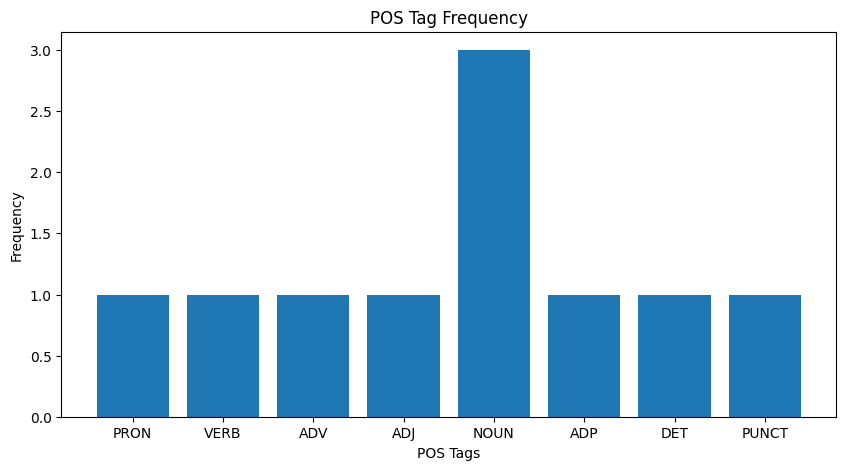

In [16]:
#12. Visualize POS tags as a bar chart
#we can count POS tags and display their frequency.
import spacy
from collections import Counter
import matplotlib.pyplot as plt
nlp = spacy.load("en_core_web_sm")
text = "There are so many stars in the sky tonight."
doc = nlp(text)
pos_counts = Counter([token.pos_ for token in doc])
plt.figure(figsize=(10, 5))
plt.bar(pos_counts.keys(), pos_counts.values())
plt.xlabel('POS Tags')
plt.ylabel('Frequency')
plt.title('POS Tag Frequency')
plt.show()

In [17]:
#13. POS visualization using displacy
#spacy can visualize part-of-speech information directly.
import spacy
from spacy import displacy
nlp = spacy.load("en_core_web_sm")
text = "She owns a mansion and a luxurious car."
doc = nlp(text)
options = {"compact":"True","distance":100}
displacy.render(doc, style="dep",options=options, jupyter=True)

In [20]:
#14. POS Tagging for a paragraph.
import spacy

nlp = spacy.load("en_core_web_sm")

text = """Cloud Computing provides storage and computing resources over the internet.
AWS, Azure, and Google Cloud are popular cloud platforms.
Businesses use cloud services to reduce infrastructure costs."""

doc = nlp(text)

for sentence in doc.sents:
    print("\nSentence:", sentence.text)

    for token in sentence:
        print(f"{token.text:15}"
              f"{token.pos_:8}"
              f"{spacy.explain(token.pos_)}")


Sentence: Cloud Computing provides storage and computing resources over the internet.

Cloud          PROPN   proper noun
Computing      PROPN   proper noun
provides       VERB    verb
storage        NOUN    noun
and            CCONJ   coordinating conjunction
computing      VERB    verb
resources      NOUN    noun
over           ADP     adposition
the            DET     determiner
internet       NOUN    noun
.              PUNCT   punctuation

              SPACE   space

Sentence: AWS, Azure, and Google Cloud are popular cloud platforms.

AWS            PROPN   proper noun
,              PUNCT   punctuation
Azure          PROPN   proper noun
,              PUNCT   punctuation
and            CCONJ   coordinating conjunction
Google         PROPN   proper noun
Cloud          PROPN   proper noun
are            AUX     auxiliary
popular        ADJ     adjective
cloud          NOUN    noun
platforms      NOUN    noun
.              PUNCT   punctuation

              SPACE   space

Sentenc

In [21]:
#15. Create a POS table.
#for teaching, a table containing word +POS +explanation is very useful.
import spacy
import pandas as pd
nlp = spacy.load("en_core_web_sm")
text = "Students learn python quickly."
doc = nlp(text)
data = []
for token in doc:
    data.append([token.text, token.pos_, spacy.explain(token.pos_)])
df = pd.DataFrame(data, columns=["Word", "POS", "Meaning"])
print(df)

       Word    POS      Meaning
0  Students   NOUN         noun
1     learn   VERB         verb
2    python   NOUN         noun
3   quickly    ADV       adverb
4         .  PUNCT  punctuation


WORD		POS
--------------------------------------------------
Deep		ADJ		adjective
learning		NOUN		noun
is		AUX		auxiliary
a		DET		determiner
powerful		ADJ		adjective
branch		NOUN		noun
of		ADP		adposition
artificial		ADJ		adjective
intelligence		NOUN		noun
.		PUNCT		punctuation

		SPACE		space
Neural		PROPN		proper noun
networks		NOUN		noun
can		AUX		auxiliary
learn		VERB		verb
complex		ADJ		adjective
patterns		NOUN		noun
from		ADP		adposition
large		ADJ		adjective
datasets		NOUN		noun
.		PUNCT		punctuation

		SPACE		space
Many		ADJ		adjective
industries		NOUN		noun
use		VERB		verb
deep		ADJ		adjective
learning		NOUN		noun
for		ADP		adposition
image		NOUN		noun
recognition		NOUN		noun
and		CCONJ		coordinating conjunction
language		NOUN		noun
processing		NOUN		noun
.		PUNCT		punctuation


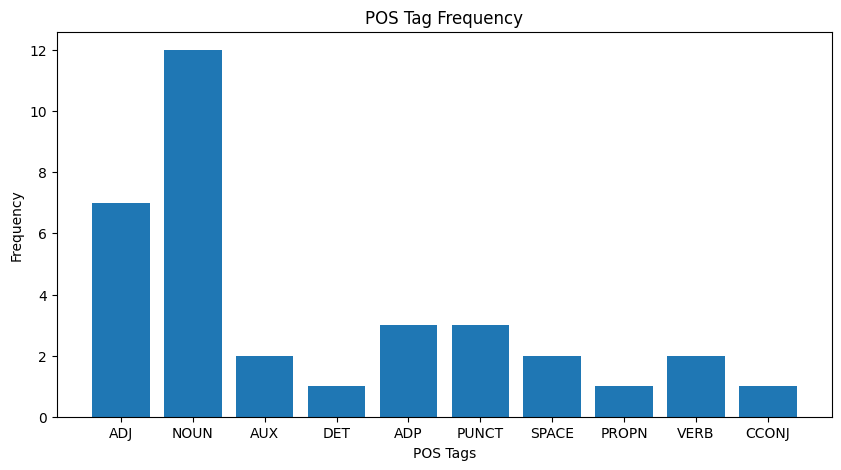

In [22]:
# Complete POS visualization Program
import spacy
from spacy import displacy
from collections import Counter
import matplotlib.pyplot as plt

# Load model
nlp = spacy.load("en_core_web_sm")

# Input text
text = """Deep learning is a powerful branch of artificial intelligence.
Neural networks can learn complex patterns from large datasets.
Many industries use deep learning for image recognition and language processing."""

# Process text
doc = nlp(text)

# Display POS Tags
print("WORD\t\tPOS")
print("-" * 50)

for token in doc:
    print(f"{token.text}\t\t{token.pos_}\t\t{spacy.explain(token.pos_)}")

# Count POS tags
pos_counts = Counter([token.pos_ for token in doc])

# Visualize POS tags as a bar chart
plt.figure(figsize=(10, 5))
plt.bar(pos_counts.keys(), pos_counts.values())
plt.xlabel('POS Tags')
plt.ylabel('Frequency')
plt.title('POS Tag Frequency')
plt.show()

# Dependency visualization
displacy.render(doc, style="dep", jupyter=True)

In [ ]:
x